# MJ-Lens on the report's pretrained VLM examples

Run MJ-Lens on **Qwen2.5-VL-3B-Instruct** using the same eight held-out image/question cases as the technical report: two each from **GQA, MMVP, VSR and VisOnlyQA**. This notebook contains the full executable workflow: raw images, native prompts and preprocessing, independent calibration, fresh probing, numerical controls and plots. It does not import an experiment runner or load saved showcase tensors.

The default calibration uses **32 independent COCO image/caption pairs**. Their source is official **COCO val2014**; the manifest's `train` label denotes an internal calibration partition, not official COCO train2014. The eight report images remain held out, and raw-file checksums detect overlap and changed downloads.

Two text-output operators are fitted: **visual-to-text (V→T)** reads decoder image-token states; **text-to-text (T→T)** reads the last prompt state. In the native image-before-question template, the earlier image states cannot depend on the later question. A displayed answer-token contrast does not change that ordering. The last prompt state can use both the image and complete question. Qwen has no discrete image-generation codebook here, so this walkthrough makes no T→V, V→V or modality-index claim.

Install from this repository with `python -m pip install -e ".[transformers,visualization]"`, then select a Python kernel with those packages. Start from the repository root or its `demos` directory. A CUDA GPU with **24 GB or more** is recommended; the default uses float32, eager attention and exact VJPs. Allow roughly **15 minutes or more on an A100-class GPU** for calibration, with runtime dependent on settings and hardware. CPU execution is supported but can be much slower.

Configuration is visible in the first code cell:

| Setting | Default | Purpose |
| --- | --- | --- |
| `VLM_PROBING_OUTPUT` | `outputs/mj_report_cases` under the checkout | Calibration artifacts, fresh measurements and figures. Choose an empty directory for a new fit. |
| `VLM_PROBING_MODEL` | `Qwen/Qwen2.5-VL-3B-Instruct` | The declared Hub checkpoint or its verified local copy. |
| `VLM_PROBING_DEVICE` | `cuda:0` when available | Compute device. |
| `VLM_PROBING_DTYPE` | `float32` | Floating dtype; changing it changes calibration identity and numerical results. |
| `VLM_PROBING_MJ_LAYERS` | `8,16,24,35` | Decoder block-input sites. |
| `VLM_PROBING_MJ_CALIBRATION` | `32` | First 2–32 manifest records; keep 32 for this default protocol. |
| `VLM_PROBING_MJ_DIM_BATCH` | `64` | Exact output-basis VJPs per backward call; reduce this to lower peak memory. |
| `VLM_PROBING_DATA_CACHE` | `~/.cache/vlmprobe/coco_calibration` | External cache for the downloaded raw COCO images. |

The calibration and evaluation pixel caps are explicit constants, **224²** and **448²** respectively; caption teacher forcing is capped at 24 tokens. Changing them creates a different protocol. To refit, choose a new empty output directory before running the cells. If matching calibration artifacts already exist, the fitting cell resumes their identity-checked accumulators, as ordinary fitted-weight caching; it still executes all held-out model forwards, readouts, controls and plots anew.

[Method and parameter guide](../docs/methods/mj_lens.md) · [Held-out input provenance](assets/mj_report_samples.json) · [Calibration manifest](assets/mj_calibration_coco.json)

## 1. Imports and reproducible configuration

Define every model, path and numerical setting used below. No pretrained MJ transport is downloaded: the backbone is pretrained, while the transport is estimated in cell 4. `%matplotlib inline` displays each figure in the notebook.

In [1]:
%matplotlib inline
import hashlib
import json
import os
import time
import textwrap
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from vlmprobe import MJBatch, Prober, visual_grid
from vlmprobe.visualization import plot_mj_visual_readout, plot_mj_text_comparison

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "demos/assets/mj_report_samples.json").is_file())
OUT = Path(os.environ.get("VLM_PROBING_OUTPUT", str(ROOT / "outputs/mj_report_cases")))
OUT.mkdir(parents=True, exist_ok=True)
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MODEL_REVISION = "66285546d2b821cf421d4f5eb2576359d3770cd3"
MODEL = os.environ.get("VLM_PROBING_MODEL", MODEL_ID)
DEVICE = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
DTYPE = getattr(torch, os.environ.get("VLM_PROBING_DTYPE", "float32"))
LAYERS = [int(x) for x in os.environ.get("VLM_PROBING_MJ_LAYERS", "8,16,24,35").split(",")]
N_CALIBRATION = int(os.environ.get("VLM_PROBING_MJ_CALIBRATION", "32"))
DIM_BATCH = int(os.environ.get("VLM_PROBING_MJ_DIM_BATCH", "64"))
CALIBRATION_PIXELS, EVALUATION_PIXELS = 224**2, 448**2
MAX_CAPTION_TOKENS = 24
CACHE = Path(os.environ.get("VLM_PROBING_DATA_CACHE", str(Path.home() / ".cache/vlmprobe/coco_calibration")))
CACHE.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0)
torch.set_num_threads(int(os.environ.get("VLM_PROBING_CPU_THREADS", "4")))
if DEVICE.startswith("cuda"):
    torch.set_float32_matmul_precision("high")


def checksum(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def write_status(state, **extra):
    payload = {"status": state, "updated_unix": time.time(), **extra}
    temp = OUT / "status.tmp.json"
    temp.write_text(json.dumps(payload, indent=2) + "\n")
    temp.replace(OUT / "status.json")
    print(json.dumps(payload), flush=True)


## 2. Raw report inputs and independent calibration records

Load the bundled original images and exact report question prompts. Validate every image's SHA-256, download the independent COCO calibration images into the external cache, and check that their bytes do not overlap the held-out images. Reference and foil answers are used only for the later readout displays and measurements.

In [2]:
report_manifest = ROOT / "demos/assets/mj_report_samples.json"
calibration_manifest = ROOT / "demos/assets/mj_calibration_coco.json"
cases = json.loads(report_manifest.read_text())["cases"]
calibration_records = json.loads(calibration_manifest.read_text())["samples"][:N_CALIBRATION]
if not 2 <= N_CALIBRATION <= 32:
    raise ValueError("choose 2..32 independent calibration images from the manifest")
for case in cases:
    case["local_image"] = ROOT / case["image_path"]
    if checksum(case["local_image"]) != case["image_sha256"]:
        raise ValueError(f"raw report image checksum mismatch: {case['id']}")
showcase_hashes = {case["image_sha256"] for case in cases}
for record in calibration_records:
    if record["image_sha256"] in showcase_hashes:
        raise ValueError("a showcase image overlaps calibration")
    path = CACHE / record["file_name"]
    if not path.exists():
        temporary = path.with_suffix(".download")
        with urlopen(record["image_url"], timeout=120) as response:
            temporary.write_bytes(response.read())
        if checksum(temporary) != record["image_sha256"]:
            temporary.unlink()
            raise ValueError("downloaded calibration image failed its checksum")
        temporary.replace(path)
    if checksum(path) != record["image_sha256"]:
        raise ValueError("cached calibration image failed its checksum")
    record["local_image"] = path
print("Held-out cases:", [(c["id"], c["answer_surface"]) for c in cases])
print("Calibration:", N_CALIBRATION, "images from COCO val2014's independent internal calibration split")


Held-out cases: [('gqa_07302654', 'Yellow'), ('gqa_19225230', 'Black'), ('mmvp-1', 'Open'), ('mmvp-2', 'Closed'), ('vsr-zeroshot-test-0', 'Yes'), ('vsr-zeroshot-test-1', 'No'), ('visonly_geometry__triangle', 'False'), ('visonly_charts__extraction', 'e')]
Calibration: 32 images from COCO val2014's independent internal calibration split


## 3. Native pretrained model, image prompts and teacher forcing

Load the actual Qwen checkpoint and processor. `prepare_image_text` constructs the native image-then-question chat prompt; the first two report cases ask whether the shirt is black or yellow. `caption_batch` instead uses only each independent calibration image and its COCO caption. It reprocesses the complete teacher-forced sequence so image positions and native token-type metadata stay aligned.

A hidden state predicts the following token. The target mask therefore starts at `prefix_length - 1` and excludes the final state, selecting states that predict supplied caption tokens and EOS. Held-out report questions and answer labels are not passed to this calibration function.

In [3]:
write_status("loading_model", model=MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL, revision=MODEL_REVISION, dtype=DTYPE, device_map={"": DEVICE}, attn_implementation="eager",
).eval().requires_grad_(False)
text_config = model.config.text_config
if (model.config.model_type != "qwen2_5_vl" or text_config.hidden_size != 2048
        or text_config.num_hidden_layers != 36):
    raise ValueError("this fixed-layer demo requires Qwen2.5-VL-3B-Instruct; adapt layers and identities for other models")
if not Path(MODEL).exists() and MODEL != MODEL_ID:
    raise ValueError("MODEL may be the declared Hub checkpoint or its local copy, not a differently labelled Hub model")
processor = AutoProcessor.from_pretrained(MODEL, revision=MODEL_REVISION, use_fast=False)
tokenizer = processor.tokenizer
model.config._name_or_path = MODEL_ID
probe = Prober(model, processor)
if any(layer not in probe.spec.mj.sources for layer in LAYERS):
    raise ValueError("selected MJ block-input indices do not exist on this checkpoint")
revision = getattr(model.config, "_commit_hash", None)
metadata_path = Path(MODEL) / ".cache/huggingface/download/config.json.metadata"
if revision is None and metadata_path.is_file():
    revision = metadata_path.read_text().splitlines()[0]
if revision != MODEL_REVISION:
    raise ValueError("use the pinned Hub revision or its local copy with matching download metadata")
print("MJ sites:", {layer: probe.spec.mj.sources[layer] for layer in LAYERS})
print("Native final target:", probe.spec.mj.final, "revision:", revision)


def prepare_image_text(image, question, max_pixels):
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": question},
    ]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    native = dict(processor(text=prompt, images=image, return_tensors="pt",
                            min_pixels=56**2, max_pixels=max_pixels))
    return prompt, {key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
                    for key, value in native.items()}


def caption_batch(record):
    image = Image.open(record["local_image"]).convert("RGB")
    prompt, prefix = prepare_image_text(image, "Describe this image in one sentence.", CALIBRATION_PIXELS)
    caption_ids = tokenizer.encode(record["caption"], add_special_tokens=False)[:MAX_CAPTION_TOKENS]
    caption = tokenizer.decode(caption_ids, skip_special_tokens=False)
    # Re-process the COMPLETE text. Appending IDs alone leaves native token-type
    # metadata at the old length in Transformers 5.3 and produces a shape error.
    native = dict(processor(text=prompt + caption + tokenizer.eos_token, images=image,
                            return_tensors="pt", min_pixels=56**2, max_pixels=CALIBRATION_PIXELS))
    prefix_length = prefix["input_ids"].shape[1]
    if not torch.equal(prefix["input_ids"].cpu(), native["input_ids"][:, :prefix_length]):
        raise ValueError("caption boundary changes prefix tokenization; inspect the native template")
    native = {key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
              for key, value in native.items()}
    for key in ("attention_mask", "mm_token_type_ids", "token_type_ids"):
        if key in native and native[key].shape != native["input_ids"].shape:
            raise ValueError(f"unaligned native sequence metadata: {key}")
    targets = torch.zeros_like(native["input_ids"], dtype=torch.bool)
    targets[:, prefix_length - 1:-1] = True  # States predicting caption tokens/EOS.
    return MJBatch(native, target_masks={"text": targets}, context="text_output")


{"status": "loading_model", "updated_unix": 1792962432.0081887, "model": "Qwen/Qwen2.5-VL-3B-Instruct"}


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

MJ sites: {8: 'residual.7', 16: 'residual.15', 24: 'residual.23', 35: 'residual.34'}
Native final target: residual.35 revision: 66285546d2b821cf421d4f5eb2576359d3770cd3


## 4. Fit both modality-specific transports

Estimate V→T and T→T operators with exact Jacobian-vector calculations while the pretrained model stays frozen. This is calibration, not backbone fine-tuning or SAE training. Each prompt contributes equally after averaging its admissible causal source/target pairs.

The output directory stores resumable accumulators and fitted calibration files. An empty directory performs a fresh fit; matching files resume calibration after identity and settings checks. The same ordered calibration records are supplied either way. Split-half cosine measures operator stability, not semantic or causal faithfulness.

In [4]:
binding = {"model_id": MODEL_ID, "model_revision": str(revision),
           "tokenizer_id": MODEL_ID + "@" + str(revision),
           "calibration_id": "coco-caption-v2:" + checksum(calibration_manifest) +
           f":first{N_CALIBRATION}:pixels{CALIBRATION_PIXELS}:cap{MAX_CAPTION_TOKENS}:dtype{DTYPE}"}
methods = {}
for source in ("visual", "text"):
    def training_inputs():
        for index, record in enumerate(calibration_records):
            write_status("calibrating", source=source, completed=index,
                         total=N_CALIBRATION, image_id=record["image_id"])
            yield caption_batch(record)
        write_status("calibrated_channel", source=source, completed=N_CALIBRATION)
    method = probe.lens.mj(layers=LAYERS, source=source, target="text", binding=binding)
    method.fit_batches(training_inputs(), directory=OUT / f"{source}_to_text",
                       dim_batch=DIM_BATCH, checkpoint_every=4,
                       resume=(OUT / f"{source}_to_text/mj_calibration_state.pt").exists())
    methods[source] = method
    print(source, "split-half operator cosine:", method.calibration_report["split_half_cosine"])


{"status": "calibrating", "updated_unix": 1792962436.7154276, "source": "visual", "completed": 0, "total": 32, "image_id": 214503}


{"status": "calibrating", "updated_unix": 1792962436.7623396, "source": "visual", "completed": 1, "total": 32, "image_id": 333294}


{"status": "calibrating", "updated_unix": 1792962436.788002, "source": "visual", "completed": 2, "total": 32, "image_id": 71171}


{"status": "calibrating", "updated_unix": 1792962436.8110418, "source": "visual", "completed": 3, "total": 32, "image_id": 274298}


{"status": "calibrating", "updated_unix": 1792962436.833351, "source": "visual", "completed": 4, "total": 32, "image_id": 573926}


...

{"status": "calibrating", "updated_unix": 1792962439.2305365, "source": "text", "completed": 29, "total": 32, "image_id": 316968}


{"status": "calibrating", "updated_unix": 1792962439.2520132, "source": "text", "completed": 30, "total": 32, "image_id": 249246}


{"status": "calibrating", "updated_unix": 1792962439.2738564, "source": "text", "completed": 31, "total": 32, "image_id": 514049}


{"status": "calibrated_channel", "updated_unix": 1792962439.29716, "source": "text", "completed": 32}


text split-half operator cosine: {'8': 0.9324982980277186, '16': 0.9342839911802356, '24': 0.9364048867764604, '35': 0.9991422149718613}


## 5. Fresh readouts and same-state controls on all eight report cases

Construct each image/question input from its raw source. Run MJ at decoder image positions and the last prompt position, obtain a plain final-normalization/head readout at exactly the same MJ source states, and collect the model's native final distribution and greedy answer.

Record exact answer/foil token IDs, token ranks, raw logit margins, native top-20 overlap and KL divergence. Target boxes are available only for the two GQA shirts and are scaled through this Qwen resize path; no boxes are invented for other datasets. These eight cases are a shared case study, not a dataset-level benchmark.

In [5]:
rows, records = [], []
for case in cases:
    image = Image.open(case["local_image"]).convert("RGB")
    prompt, inputs = prepare_image_text(image, case["prompt_question"], EVALUATION_PIXELS)
    geometry = visual_grid(probe, inputs)["grids"][0]
    grid = tuple(geometry["grid_shape"])
    raw_grid = inputs["image_grid_thw"][0].tolist()
    patch_size = model.config.vision_config.patch_size
    processed_size = (raw_grid[2] * patch_size, raw_grid[1] * patch_size)
    # Qwen uses a resize-only still-image path here; retain its measured grid,
    # explicit resize and bbox scale. No crop, padding or tiling is guessed.
    processed_image = image.resize(processed_size, Image.Resampling.BICUBIC)
    bbox = case.get("bbox_xywh")
    if bbox is not None:
        sx, sy = processed_size[0] / image.width, processed_size[1] / image.height
        bbox = [bbox[0] * sx, bbox[1] * sy, bbox[2] * sx, bbox[3] * sy]
    positive_ids = tokenizer.encode(case["answer_surface"], add_special_tokens=False)
    negative_ids = tokenizer.encode(case["other_answer_surface"], add_special_tokens=False)
    if len(positive_ids) != 1 or len(negative_ids) != 1 or positive_ids == negative_ids:
        raise ValueError(f"this fixed-token demo requires distinct single-token choices: {case['id']}")
    positive, negative = positive_ids[0], negative_ids[0]
    vt = methods["visual"].run(inputs)
    tt = methods["text"].run(inputs, tokens="last_prompt")
    trace = probe._run(inputs, capture=[probe.spec.mj.sources[l] for l in LAYERS])
    last = int(probe._layout(inputs, trace.logits).select("last_prompt").nonzero()[0, 1])
    native = trace.logits[0, last].detach().float().cpu()
    with torch.no_grad():
        plain = torch.stack([probe.adapter.readout(trace.activations[probe.spec.mj.sources[l]][:, last])
                             for l in LAYERS]).detach().float().cpu()
        output = model.generate(**inputs, max_new_tokens=12, do_sample=False,
                                pad_token_id=tokenizer.pad_token_id)
    generated = tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    native_logp = native.log_softmax(-1)
    native_top = set(native.topk(20).indices.tolist())
    metrics = []
    for index, layer in enumerate(LAYERS):
        measured = {"layer": layer}
        for name, logits in (("mj", tt.tensors["logits"][index, 0]), ("plain", plain[index, 0])):
            logits = logits.float()
            measured[name + "_answer_rank"] = int((logits > logits[positive]).sum()) + 1
            measured[name + "_margin"] = float(logits[positive] - logits[negative])
            measured[name + "_native_top20_overlap"] = len(native_top & set(logits.topk(20).indices.tolist())) / 20
            measured[name + "_kl_native"] = float((native_logp.exp() * (native_logp - logits.log_softmax(-1))).sum())
            measured[name + "_top_tokens"] = [tokenizer.decode([i]) for i in logits.topk(5).indices.tolist()]
        metrics.append(measured)
    record = {"id": case["id"], "dataset": case["dataset"], "question": case["question"],
              "prompt_question": case["prompt_question"], "answer": case["answer_surface"],
              "foil": case["other_answer_surface"], "generated": generated,
              "native_margin": float(native[positive] - native[negative]),
              "native_answer_rank": int((native > native[positive]).sum()) + 1,
              "answer_token_id": positive, "foil_token_id": negative,
              "image_sha256": case["image_sha256"], "processed_size": processed_size,
              "grid_shape": grid, "bbox_processed": bbox, "metrics": metrics}
    records.append(record)
    rows.append({"case": case, "inputs": inputs, "image": processed_image, "bbox": bbox,
                 "grid": grid, "positive": positive, "negative": negative,
                 "vt": vt, "tt": tt, "native": native, "plain": plain, "record": record})
    write_status("evaluating", completed=len(rows), total=len(cases), case=case["id"],
                 generated=generated, answer=case["answer_surface"])


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{"status": "evaluating", "updated_unix": 1792962441.4286344, "completed": 1, "total": 8, "case": "gqa_07302654", "generated": "Yellow", "answer": "Yellow"}


{"status": "evaluating", "updated_unix": 1792962442.5604615, "completed": 2, "total": 8, "case": "gqa_19225230", "generated": "Black", "answer": "Black"}


{"status": "evaluating", "updated_unix": 1792962443.2201006, "completed": 3, "total": 8, "case": "mmvp-1", "generated": "Open", "answer": "Open"}


{"status": "evaluating", "updated_unix": 1792962443.8495462, "completed": 4, "total": 8, "case": "mmvp-2", "generated": "Open", "answer": "Closed"}


{"status": "evaluating", "updated_unix": 1792962444.9366562, "completed": 5, "total": 8, "case": "vsr-zeroshot-test-0", "generated": "No", "answer": "Yes"}


{"status": "evaluating", "updated_unix": 1792962446.024458, "completed": 6, "total": 8, "case": "vsr-zeroshot-test-1", "generated": "No", "answer": "No"}


{"status": "evaluating", "updated_unix": 1792962446.5514557, "completed": 7, "total": 8, "case": "visonly_geometry__triangle", "generated": "False", "answer": "False"}


{"status": "evaluating", "updated_unix": 1792962447.6797545, "completed": 8, "total": 8, "case": "visonly_charts__extraction", "generated": "a", "answer": "e"}


## 6. Spatial vocabulary readouts on the paired report photographs

First inspect all eight original images with their questions, reference answers and freshly generated model answers. Then compare the two GQA shirt photographs and two MMVP butterfly photographs across the selected block-input layers. Every overlay displays the reference-answer token logit minus its foil at decoder image-token states. Orange boxes mark the supplied GQA annotations.

Colors are scaled independently for each map. A vocabulary readout is not attention, causal attribution, object detection or evidence that the early image state has seen the later question. Exact tokenizer pieces need not correspond to whole-word concepts.

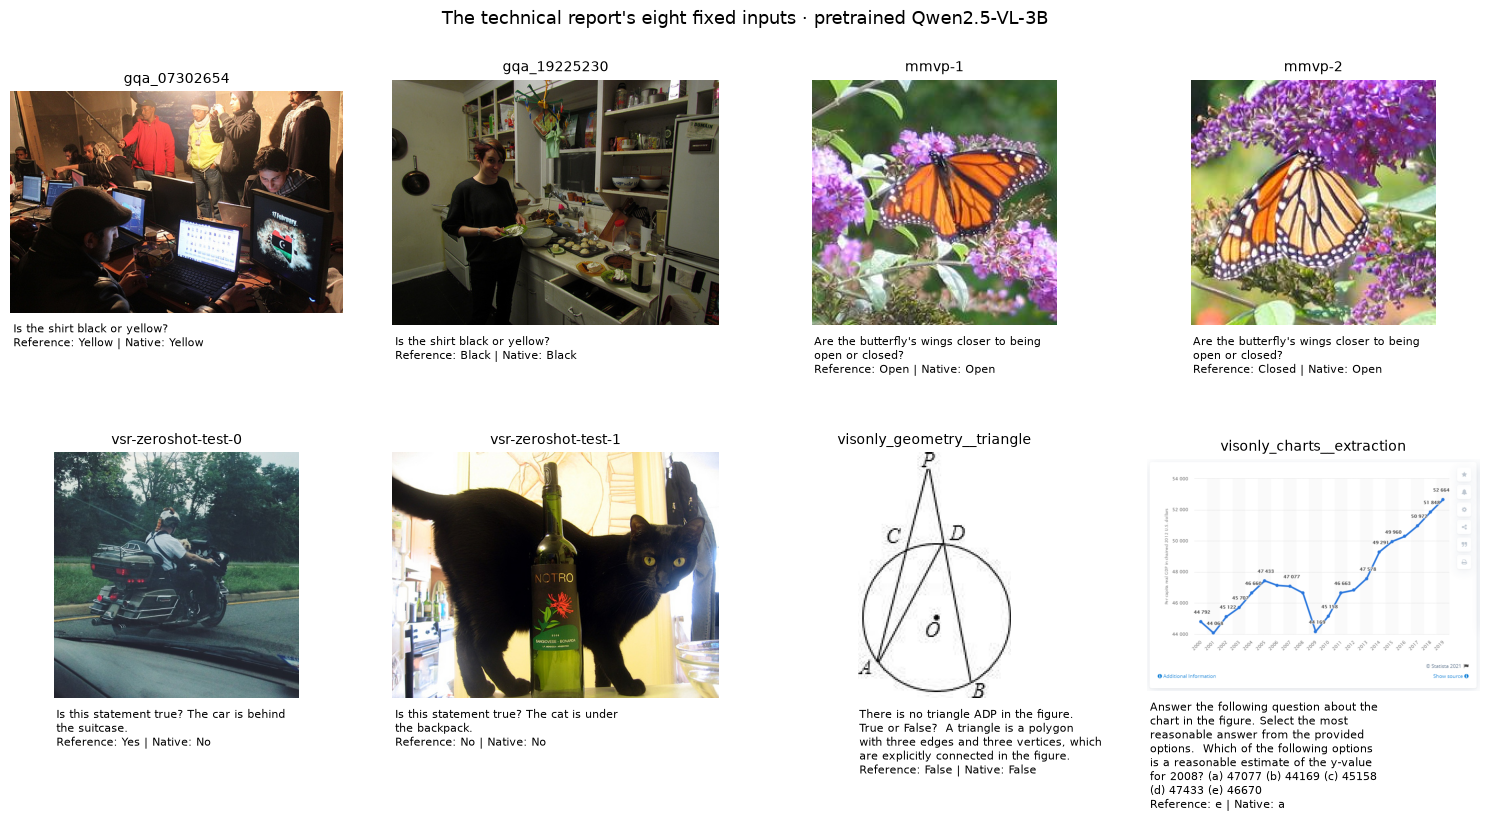

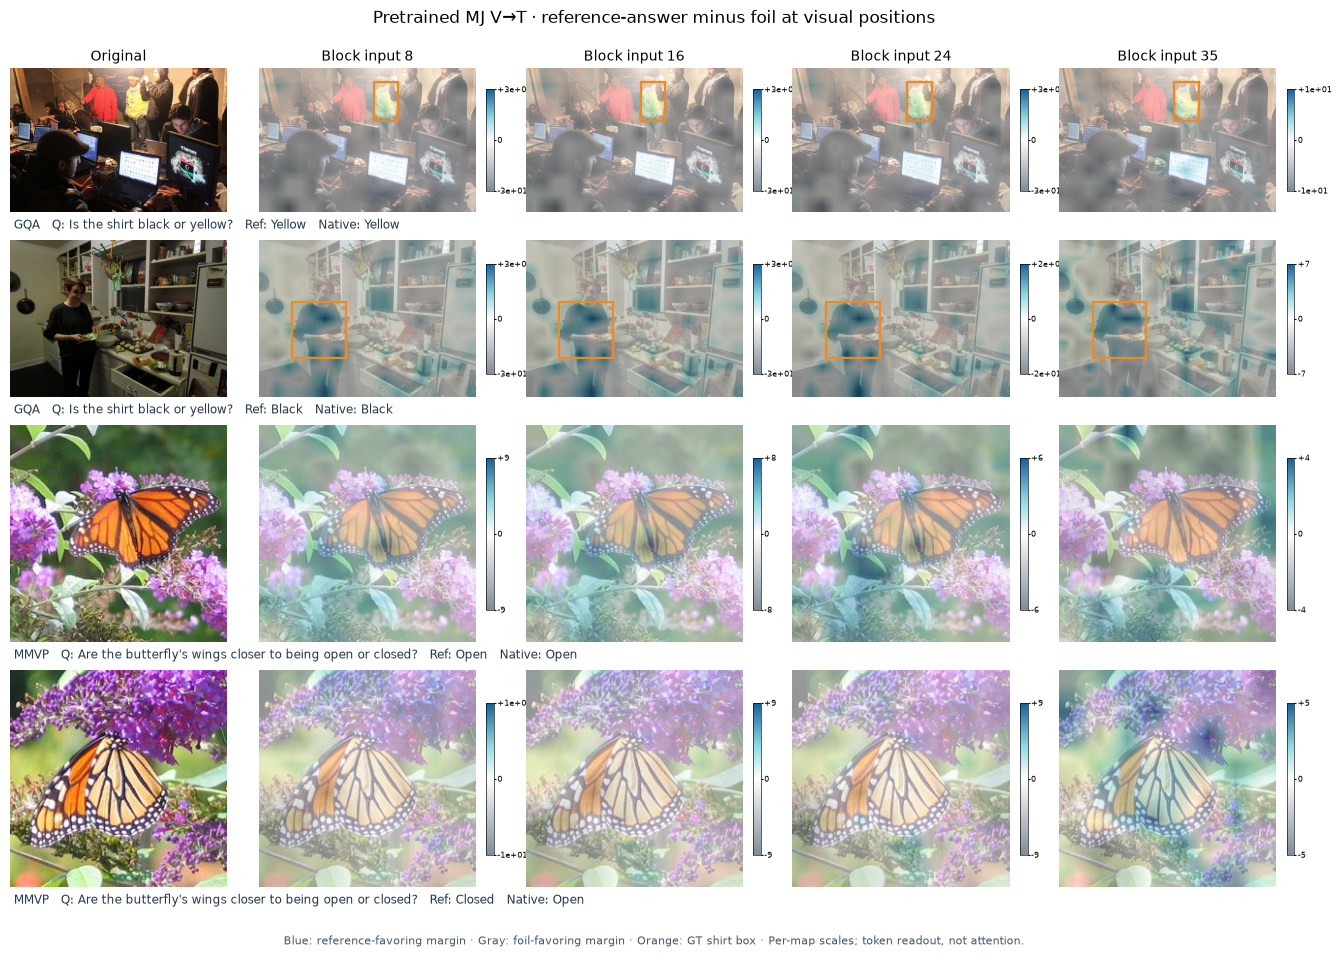

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8), squeeze=False)
for row, ax in zip(rows, axes.flat):
    ax.imshow(Image.open(row["case"]["local_image"]).convert("RGB"))
    ax.axis("off")
    ax.set_title(row["case"]["id"], fontsize=10)
    ax.text(.01, -.04, textwrap.fill(row["case"]["question"], 42) +
            f"\nReference: {row['record']['answer']} | Native: {row['record']['generated']}",
            transform=ax.transAxes, va="top", fontsize=8)
fig.suptitle("The technical report's eight fixed inputs · pretrained Qwen2.5-VL-3B", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .96), h_pad=5)
fig.savefig(OUT / "mj-report-inputs.png", dpi=180, bbox_inches="tight")
plt.show()

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.ticker import FuncFormatter

spatial_rows = rows[:4]
# Match each row's height to its measured image aspect ratio. Captions occupy
# separate narrow strips, so landscape images do not create blank square rows.
row_ratios = [row["image"].height / row["image"].width for row in spatial_rows]
height_ratios = [value for ratio in row_ratios for value in (ratio, .105)]
fig = plt.figure(figsize=(13.2, 2.48 * sum(row_ratios) + 1.2))
grid = fig.add_gridspec(2 * len(spatial_rows), 1 + len(LAYERS),
    height_ratios=height_ratios, width_ratios=[1.] + [1.1] * len(LAYERS),
    left=.012, right=.985, bottom=.045, top=.925, wspace=.12, hspace=.025)
readout_cmap = LinearSegmentedColormap.from_list("mj_spatial_signed", [
    (0., "#7f8d99"), (.5, "#ffffff"), (.72, "#8dd7e1"), (1., "#155f9e"),
])
for row_index, row in enumerate(spatial_rows):
    ax = fig.add_subplot(grid[2 * row_index, 0])
    ax.imshow(row["image"])
    ax.axis("off")
    if row_index == 0:
        ax.set_title("Original", fontsize=10, pad=5)
    for column, layer in enumerate(LAYERS, 1):
        # The narrow colorbar belongs to this map only. Its symmetric limits
        # expose the measured sign and units without changing any readout.
        cell = GridSpecFromSubplotSpec(1, 2, subplot_spec=grid[2 * row_index, column],
                                      width_ratios=[1., .035], wspace=.055)
        map_ax = fig.add_subplot(cell[0, 0])
        plot_mj_visual_readout(row["image"], row["vt"], positive_token_id=row["positive"],
            negative_token_id=row["negative"], grid_shape=row["grid"], layer=layer,
            bbox=row["bbox"], token_label=row["record"]["answer"], negative_label=row["record"]["foil"],
            image_alpha=.45, alpha=1., cmap=readout_cmap, colorbar=False, ax=map_ax)
        map_ax.set_title(f"Block input {layer}" if row_index == 0 else "", fontsize=10, pad=5)
        bar_ax = fig.add_subplot(cell[0, 1])
        # Vertically center a short bar next to the actual image artist.
        bar_box = bar_ax.get_position()
        bar_ax.set_position([bar_box.x0, bar_box.y0 + .15 * bar_box.height,
                             bar_box.width, .70 * bar_box.height])
        artist = map_ax.images[1]
        limits = [artist.norm.vmin, 0., artist.norm.vmax]
        colorbar = fig.colorbar(artist, cax=bar_ax, ticks=limits,
            format=FuncFormatter(lambda value, _: "0" if value == 0 else f"{value:+.1g}"))
        colorbar.ax.tick_params(labelsize=5.7, length=1.5, pad=1)
        colorbar.outline.set_linewidth(.45)
    caption_ax = fig.add_subplot(grid[2 * row_index + 1, :])
    caption_ax.axis("off")
    caption_ax.text(.003, .55,
        f"{row['case']['dataset']}   Q: {row['case']['question']}   "
        f"Ref: {row['record']['answer']}   Native: {row['record']['generated']}",
        transform=caption_ax.transAxes, ha="left", va="center", fontsize=8.5, color="#26384c")
fig.suptitle("Pretrained MJ V→T · reference-answer minus foil at visual positions", y=.985, fontsize=12)
fig.text(.5, .012,
    "Blue: reference-favoring margin · Gray: foil-favoring margin · Orange: GT shirt box · "
    "Per-map scales; token readout, not attention.", ha="center", fontsize=7.8, color="#45566b")
fig.savefig(OUT / "mj-report-spatial.png", dpi=180, bbox_inches="tight")
plt.show()


## 7. Question-conditioned text readouts and controls

Use the last prompt state, which can attend to both the image and complete question. Blue shows MJ-Lens; gray shows the plain readout of the same intermediate state; orange marks the actual final output margin. Values remain raw signed answer-versus-foil logit margins, so the curves do not receive separate normalization. There is no assumption that MJ must improve every layer or example.

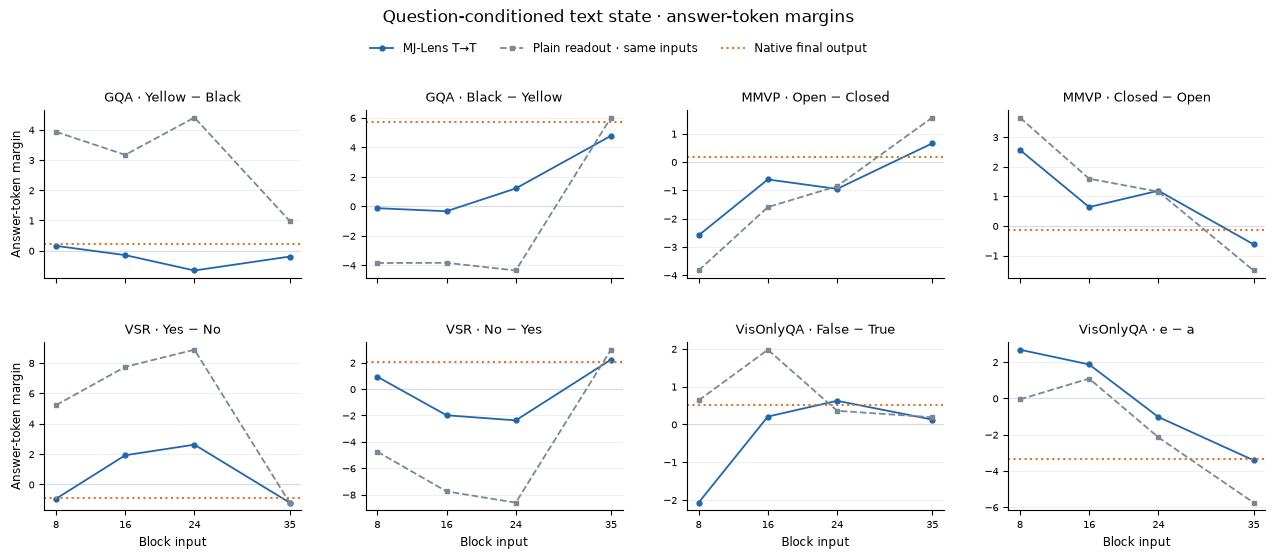

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(13.2, 5.6), squeeze=False, sharex=True)
for index, (row, ax) in enumerate(zip(rows, axes.flat)):
    plot_mj_text_comparison(row["tt"], row["plain"], row["native"],
        positive_token_id=row["positive"], negative_token_id=row["negative"], ax=ax)
    ax.set_title(f"{row['case']['dataset']} · {row['record']['answer']} − {row['record']['foil']}", fontsize=9.5)
    ax.set_xlabel("Block input" if index >= 4 else "", fontsize=8.5)
    ax.set_ylabel("Answer-token margin" if index % 4 == 0 else "", fontsize=8.5)
    ax.tick_params(labelsize=7.5)
    ax.grid(axis="y", color="#d9dfe6", linewidth=.6, alpha=.55)
    ax.spines[["top", "right"]].set_visible(False)
    for line in ax.lines[:2]:
        line.set_markersize(3.5)
        line.set_linewidth(1.3)
    ax.get_legend().remove()
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Question-conditioned text state · answer-token margins", y=.99, fontsize=12)
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(.5, .95),
           ncol=3, frameon=False, fontsize=8.5)
fig.subplots_adjust(left=.065, right=.99, bottom=.095, top=.81, wspace=.25, hspace=.38)
fig.savefig(OUT / "mj-report-text-controls.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Native-output fidelity and a causal-order check

Aggregate native-output KL divergence and top-20 overlap over the eight fixed questions, separately for MJ and plain readouts. Fidelity to the native final distribution and correctness on a reference answer are different measurements.

Then change the question while keeping the first GQA image and native image prefix fixed. The alternate question has the same token count, so matrix shapes also match; shorter prompts can otherwise change floating-point kernel behavior under TF32. Report the actual image-source readout difference in the standard causal image-before-question order. This control checks the source-state interpretation; it does not make the image readout question-conditioned.

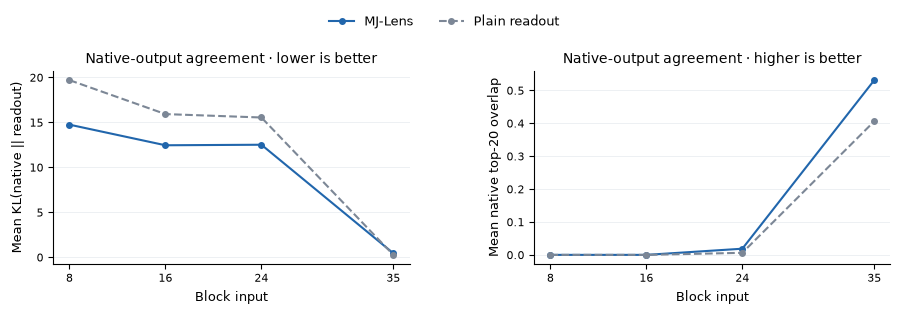

Same-image visual readout change under a later-question swap: 0.0
Length-matched questions share the exact image prefix; this is a causal-order check.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.1))
for name, color, style in (("mj", "#2166ac", "-"), ("plain", "#7c8796", "--")):
    kl = torch.tensor([[m[name + "_kl_native"] for m in r["metrics"]] for r in records])
    overlap = torch.tensor([[m[name + "_native_top20_overlap"] for m in r["metrics"]] for r in records])
    label = "MJ-Lens" if name == "mj" else "Plain readout"
    axes[0].plot(LAYERS, kl.mean(0), style, marker="o", markersize=4, color=color, label=label)
    axes[1].plot(LAYERS, overlap.mean(0), style, marker="o", markersize=4, color=color, label=label)
axes[0].set(xlabel="Block input", ylabel="Mean KL(native || readout)", title="Native-output agreement · lower is better")
axes[1].set(xlabel="Block input", ylabel="Mean native top-20 overlap", title="Native-output agreement · higher is better")
for ax in axes:
    ax.set_xticks(LAYERS)
    ax.tick_params(labelsize=8)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)
    ax.title.set_size(10)
    ax.grid(axis="y", color="#d9dfe6", linewidth=.6, alpha=.55)
    ax.spines[["top", "right"]].set_visible(False)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(.5, 1.02),
           ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(left=.075, right=.985, bottom=.18, top=.80, wspace=.35)
fig.savefig(OUT / "mj-report-fidelity.png", dpi=180, bbox_inches="tight")
plt.show()

first = rows[0]
swap_question = ("Is the shirt red or blue?\n"
                 "Answer with exactly one of: Red, Blue. Do not add punctuation or explanation.")
_, swapped_inputs = prepare_image_text(Image.open(first["case"]["local_image"]).convert("RGB"),
                                        swap_question, EVALUATION_PIXELS)
# Match sequence length and all image-prefix inputs as well as image bytes.
# With TF32, a shorter suffix can select different matrix kernels and perturb
# the computed prefix even though the mathematical decoder is strictly causal.
original_ids, swapped_ids = first["inputs"]["input_ids"], swapped_inputs["input_ids"]
prefix_end = int(first["vt"].tensors["positions"][:, 1].max()) + 1
if (original_ids.shape != swapped_ids.shape
        or not torch.equal(original_ids[:, :prefix_end], swapped_ids[:, :prefix_end])
        or not torch.equal(first["inputs"]["pixel_values"], swapped_inputs["pixel_values"])
        or not torch.equal(first["inputs"]["image_grid_thw"], swapped_inputs["image_grid_thw"])):
    raise ValueError("question-swap control requires identical image-prefix inputs and sequence lengths")
original_control = methods["visual"].run(first["inputs"])
swapped = methods["visual"].run(swapped_inputs)
question_swap_max = float((original_control.tensors["logits"] - swapped.tensors["logits"]).abs().max())
print("Same-image visual readout change under a later-question swap:", question_swap_max)
print("Length-matched questions share the exact image prefix; this is a causal-order check.")


## 9. Save/load round trip and measured results

Load the identity-bound fitted text transport and run the first held-out question again to verify the artifact round trip. Write actual measurements and runtime metadata to `experiment.json`, alongside the four figures. Saved calibration files may be reused; showcase measurements and plots above are computed by the current execution. Interpret results within this one-model, eight-case protocol.

In [9]:
restored = probe.lens.mj(layers=LAYERS, source="text", target="text", binding=binding).load(OUT / "text_to_text")
replayed = restored.run(rows[0]["inputs"], tokens="last_prompt")
roundtrip = float((replayed.tensors["logits"] - rows[0]["tt"].tensors["logits"]).abs().max())
summary = {"model_id": MODEL_ID, "revision": revision, "dtype": str(DTYPE), "layers": LAYERS,
           "torch_version": torch.__version__,
           "transformers_version": __import__("transformers").__version__,
           "seed": 0, "float32_matmul_precision": torch.get_float32_matmul_precision(),
           "calibration_max_pixels": CALIBRATION_PIXELS, "evaluation_max_pixels": EVALUATION_PIXELS,
           "caption_max_tokens": MAX_CAPTION_TOKENS, "dim_batch": DIM_BATCH,
           "image_processor_class": type(processor.image_processor).__name__,
           "n_calibration": N_CALIBRATION, "calibration_image_ids": [r["image_id"] for r in calibration_records],
           "calibration_manifest_sha256": checksum(calibration_manifest),
           "report_manifest_sha256": checksum(report_manifest),
           "calibration": {k: v.calibration_report for k, v in methods.items()},
           "records": records, "question_swap_visual_max_abs_diff": question_swap_max,
           "question_swap_visual_relative_diff": question_swap_max / max(1., float(first["vt"].tensors["logits"].abs().max())),
           "question_swap_control": {"question": swap_question, "length_matched": True,
                                     "identical_image_prefix": True,
                                     "sequence_length": original_ids.shape[1]},
           "save_load_max_abs_diff": roundtrip,
           "scope": "Eight fixed report cases on one pretrained checkpoint; not a dataset benchmark or causal attribution study"}
(OUT / "experiment.json").write_text(json.dumps(summary, indent=2) + "\n")
print("case | reference | native | final MJ answer rank | plain answer rank")
for record in records:
    metric = record["metrics"][-1]
    print(record["id"], record["answer"], repr(record["generated"]),
          metric["mj_answer_rank"], metric["plain_answer_rank"], sep=" | ")
print("\nDecoded vocabulary readouts for the two shirt examples (whitespace preserved):")
print("case | block input | MJ top-1 token | plain top-1 token")
for record in records[:2]:
    for metric in record["metrics"]:
        print(record["id"], metric["layer"], repr(metric["mj_top_tokens"][0]),
              repr(metric["plain_top_tokens"][0]), sep=" | ")
write_status("complete", n_calibration=N_CALIBRATION, n_showcase=len(records),
             question_swap_visual_max_abs_diff=question_swap_max, save_load_max_abs_diff=roundtrip)
print("Figures and measured records:", OUT)


case | reference | native | final MJ answer rank | plain answer rank
gqa_07302654 | Yellow | 'Yellow' | 2 | 1
gqa_19225230 | Black | 'Black' | 1 | 1
mmvp-1 | Open | 'Open' | 1 | 1
mmvp-2 | Closed | 'Open' | 2 | 2
vsr-zeroshot-test-0 | Yes | 'No' | 2 | 2
vsr-zeroshot-test-1 | No | 'No' | 1 | 1
visonly_geometry__triangle | False | 'False' | 1 | 1
visonly_charts__extraction | e | 'a' | 6 | 5

Decoded vocabulary readouts for the two shirt examples (whitespace preserved):
case | block input | MJ top-1 token | plain top-1 token
gqa_07302654 | 8 | ' Gäste' | '(___'
gqa_07302654 | 16 | '点儿' | '个项目'
gqa_07302654 | 24 | '<|im_end|>' | '.bunifuFlatButton'
gqa_07302654 | 35 | 'Black' | 'Yellow'
gqa_19225230 | 8 | ' Gäste' | '(___'
gqa_19225230 | 16 | '点儿' | '胜负'
gqa_19225230 | 24 | '<|im_end|>' | '应用查看'
gqa_19225230 | 35 | 'Black' | 'Black'
{"status": "complete", "updated_unix": 1792962457.3126144, "n_calibration": 32, "n_showcase": 8, "question_swap_visual_max_abs_diff": 0.0, "save_load_max_abs_d

Figures and measured records: outputs/mj_report_cases


## Interpreting this execution

This fixed-case run exposes a limitation as well as the API: split-half calibration stability does not ensure meaningful decoded words. At block inputs 8/16/24, text-state top tokens are often unrelated to the answer. At input 35, MJ matches 4 of 8 reference answers; the native model and plain same-state readout match 5. MJ has greater native top-20 overlap at this layer but worse mean KL. Inspect the decoded tokens and both fidelity controls rather than assuming a general improvement. These counts describe this one-model case study, not dataset-level accuracy.

Spatial colors show the exact reference-token minus foil-token logit margin. They do not show question-conditioned attention or causal localization.
